#Part 2 EDA: For QA Models

## Objectives:

*   Load and combine datasets from HuggingFace
*   Filter out for null values
*   Remove question and answer pairs with images that aren't usuable
*   Handle unusual question and answers
*   Fill in Amazon Textract Values from the tar files
*   EDA on context and answer sizes
*   Is context suitable for QA (Does answer exist)?






####

In [1]:
# Standard
import os
import re
import json
import tarfile
from collections import defaultdict
from difflib import SequenceMatcher
from typing import Any, Dict, List, Optional

# For EDA
import nltk
import duckdb
import numpy as np
import pandas as pd
import seaborn as sns
from nltk.corpus import words
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from sklearn.model_selection import train_test_split
from google.colab import drive

In [2]:
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
repo_name = "AmazonScience/WikiDT"

split_files = {
    "train" : "WikiDT-dataset/samples/train.json",
    "val" : "WikiDT-dataset/samples/val.json",
    "test" : "WikiDT-dataset/samples/test.json"
}


In [4]:
#Download the split files from the Hugging Face Hub
combined_data = {}
for split_name, file_path in split_files.items():
    try:
        path = hf_hub_download(repo_id=repo_name, filename=file_path, repo_type="dataset")
        combined_data[split_name] = path
    except Exception:
        print(f"Failed to download {file_path} from {repo_name}. Trying next split...")
        continue

In [5]:
#Download the OCR tar file from the Hugging Face Hub
ocr_tar_path = hf_hub_download(
    repo_id=repo_name,
    filename="WikiDT-dataset/ocr.tar",
    repo_type="dataset",
)

In [6]:
#Images for question and answer pairs that are usuable (images with no sub images)
usable_images_path = f'/content/drive/MyDrive/266_Final/data/primary_table_image_dataset.parquet'
usable_images = pd.read_parquet(usable_images_path)
print(f'shape: {usable_images.shape}')

shape: (16794, 7)


In [7]:
usable_images

,image_name,image_path,file_size_mb,num_subpages,num_tables,num_annotated_subpages,eda_status
0,10006830_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,1.448,2,3,2,usable_table_image
1,10007452_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,1.001,2,6,2,usable_table_image
2,10015132_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,2.051,5,25,5,usable_table_image
3,10015518_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,2.329,3,12,3,usable_table_image
4,10017154_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,7.121,10,36,10,usable_table_image
...,...,...,...,...,...,...,...
16789,30108930_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,1.672,4,13,4,usable_table_image
16790,30133_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,6.802,6,12,6,usable_table_image
16791,30134667_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,0.937,3,11,3,usable_table_image
16792,30139175_page.png,/content/drive/MyDrive/WikiDT_Persistent/data/...,2.269,3,6,3,usable_table_image


# Load files from train, test, and validate and combine it to one

In [8]:
con = duckdb.connect()

stage_info = []

for split_name, file_path in combined_data.items():
    print(f"Loading {split_name} from {file_path}...")
    stage_split_info = con.execute(f"""
        SELECT
            sample_id,
            image,
            question,
            json_extract_string(answer, '$[0][0]') AS answer,
            ocr_retrieval_file_textract,
            all_ocr_files_textract,
            '{split_name}' AS original_split
        FROM read_json(
            '{file_path}',
            columns={{
                'sample_id': 'VARCHAR',
                'image': 'VARCHAR',
                'question': 'VARCHAR',
                'answer': 'JSON',
                'ocr_retrieval_file_textract': 'VARCHAR',
                'all_ocr_files_textract': 'VARCHAR[]'
            }}
        )
    """).df()
    stage_info.append(stage_split_info)

df_all = pd.concat(stage_info, ignore_index=True)
total_combined_rows = len(df_all)
print(f"Total pooled QA pairs loaded: {total_combined_rows:,}")


Loading train from /root/.cache/huggingface/hub/datasets--AmazonScience--WikiDT/snapshots/db803a4c2031b7170063fed7bc0c445cb8aec9f6/WikiDT-dataset/samples/train.json...
Loading val from /root/.cache/huggingface/hub/datasets--AmazonScience--WikiDT/snapshots/db803a4c2031b7170063fed7bc0c445cb8aec9f6/WikiDT-dataset/samples/val.json...
Loading test from /root/.cache/huggingface/hub/datasets--AmazonScience--WikiDT/snapshots/db803a4c2031b7170063fed7bc0c445cb8aec9f6/WikiDT-dataset/samples/test.json...
Total pooled QA pairs loaded: 70,652


In [9]:
df_all

,sample_id,image,question,answer,ocr_retrieval_file_textract,all_ocr_files_textract,original_split
0,0,204_232_page.png,was chile below or above the gold medal count ...,None,ocr/textract/204_232_page_seg_1.json,"[ocr/textract/204_232_page_seg_0.json, ocr/tex...",train
1,1,203_700_page.png,in 2012 who was expected to light the tree?,None,ocr/textract/203_700_page_seg_0.json,[ocr/textract/203_700_page_seg_0.json],train
2,2,204_833_page.png,which player scored the largest number of poin...,None,ocr/textract/204_833_page_seg_3.json,"[ocr/textract/204_833_page_seg_0.json, ocr/tex...",train
3,3,203_490_page.png,number of wins in the season.,None,ocr/textract/203_490_page_seg_0.json,[ocr/textract/203_490_page_seg_0.json],train
4,4,203_76_page.png,"which driver in the top 8, drives a mclaran-me...",None,ocr/textract/203_765_page_seg_0.json,"[ocr/textract/203_76_page_seg_0.json, ocr/text...",train
...,...,...,...,...,...,...,...
70647,14245,1226335_page.png,"After 1972, how many points did Marlboro Team ...",0,ocr/textract/1226335_page_seg_1.json,"[ocr/textract/1226335_page_seg_0.json, ocr/tex...",test
70648,14246,1226335_page.png,What chassis had 39 points?,tyrrell 007,ocr/textract/1226335_page_seg_1.json,"[ocr/textract/1226335_page_seg_0.json, ocr/tex...",test
70649,14247,1226335_page.png,How many points did the Ford V8 with a Tyrrell...,14,ocr/textract/1226335_page_seg_1.json,"[ocr/textract/1226335_page_seg_0.json, ocr/tex...",test
70650,14248,1226335_page.png,"Before 1976 and with 12 points, what chassis d...",tyrrell 007,ocr/textract/1226335_page_seg_1.json,"[ocr/textract/1226335_page_seg_0.json, ocr/tex...",test


# Filter out for null values

In [10]:
# Load the OCR tar file and index its members
print("Indexing members in ocr.tar...")
with tarfile.open(ocr_tar_path, "r") as tar:
    tar_members = set(tar.getnames())

available_textract_files = set()
for m in tar_members:
    clean = m.lstrip("./")
    if clean.startswith("WikiDT-dataset/"):
        clean = clean.replace("WikiDT-dataset/", "")
    if clean.startswith("ocr/textract/"):
        available_textract_files.add(clean)

print(f"Total available Textract OCR files in archive: {len(available_textract_files):,}")

Indexing members in ocr.tar...
Total available Textract OCR files in archive: 52,654


In [11]:
#Define a function to map each row to its corresponding OCR file, checking both primary and fallback options
def audit_row_coverage(row):
    primary = str(row["ocr_retrieval_file_textract"]).lstrip("./")
    if primary in available_textract_files:
        return "primary_match", primary

    fallbacks = row["all_ocr_files_textract"]
    if isinstance(fallbacks, (list, np.ndarray)):
        for fb in fallbacks:
            clean_fb = str(fb).lstrip("./")
            if clean_fb in available_textract_files:
                return "fallback_match", clean_fb

    return "missing", None

audit_results = df_all.apply(audit_row_coverage, axis=1)
df_all["mapping_status"] = [res[0] for res in audit_results]
df_all["resolved_ocr_path"] = [res[1] for res in audit_results]

In [12]:
# Apply the audit function to the DataFrame and summarize the results
statuses = [res[0] for res in audit_results]
primary_count = statuses.count("primary_match")
fallback_count = statuses.count("fallback_match")
missing_count = statuses.count("missing")
total_rows = len(statuses)

print(f"Primary Target Matches:   {primary_count:>7,} ({primary_count / total_rows * 100:>6.2f}%)")
print(f"Fallback Segment Matches: {fallback_count:>7,} ({fallback_count / total_rows * 100:>6.2f}%)")
print(f"Missing (Dropped):        {missing_count:>7,} ({missing_count / total_rows * 100:>6.2f}%)")
print(f"Total Usable OCR Rows:    {primary_count + fallback_count:>7,} ({(primary_count + fallback_count) / total_rows * 100:>6.2f}%)")

Primary Target Matches:    69,316 ( 98.11%)
Fallback Segment Matches:   1,209 (  1.71%)
Missing (Dropped):            127 (  0.18%)
Total Usable OCR Rows:     70,525 ( 99.82%)


In [13]:
# Filter the DataFrame to retain only rows with valid OCR mappings
df_filtered = df_all[df_all["mapping_status"] != "missing"].copy().reset_index(drop=True)
total_retained_rows = len(df_filtered)

print(f"Total Initial Pooled Rows:     {total_combined_rows:>8,}")
print(f"Retained (Valid OCR Target):   {total_retained_rows:>8,} ({total_retained_rows / total_combined_rows * 100:>6.2f}%)")
print(f"Dropped (Missing OCR):         {total_combined_rows - total_retained_rows:>8,} ({(total_combined_rows - total_retained_rows) / total_combined_rows * 100:>6.2f}%)")
print(f"Unique Retained Documents:     {df_filtered['image'].nunique():>8,}")

Total Initial Pooled Rows:       70,652
Retained (Valid OCR Target):     70,525 ( 99.82%)
Dropped (Missing OCR):              127 (  0.18%)
Unique Retained Documents:       14,148


# Remove question and answer pairs with images that aren't usuable

In [14]:
print(f"Before filtering for only usable images: {len(df_filtered)}")
df_filtered = df_filtered[df_filtered['image'].isin(usable_images['image_name'])]
print(f"After filtering for only usable images: {len(df_filtered)}")

Before filtering for only usable images: 70525
After filtering for only usable images: 70525


# Handle unusual question and answers

In [15]:
def filter_by_column_rules(
    df: pd.DataFrame,
    rules: Dict[str, Dict[str, Any]],
    how: str = "all"
) -> pd.DataFrame:
    """
    Filters a DataFrame using per-column configurations.

    rules structure:
    {
        "column_name": {
            "allow_null": bool,          # True to keep NaN/None, False to drop them
            "exclude_values": list       # String tokens to drop (e.g. ["", "error"])
        }
    }
    """
    validity_matrix = pd.DataFrame(index=df.index)

    for col, config in rules.items():
        if col not in df.columns:
            continue

        allow_null = config.get("allow_null", False)
        exclude_values = {
            str(val).strip().lower()
            for val in config.get("exclude_values", [])
        }

        # 1. Null handling
        is_null = df[col].isnull()
        if allow_null:
            null_condition = pd.Series(True, index=df.index)
        else:
            null_condition = ~is_null

        # 2. Token exclusion handling (only check non-null entries)
        cleaned_str = df[col].fillna("__NA_PLACEHOLDER__").astype(str).str.strip().str.lower()
        token_condition = ~cleaned_str.isin(exclude_values)

        validity_matrix[col] = null_condition & token_condition

    final_mask = validity_matrix.all(axis=1) if how == "all" else validity_matrix.any(axis=1)
    return df[final_mask]

In [16]:
rules = {
    "question": {
        "allow_null": False,
        "exclude_values": ["", "none", "nan", "null"]
    },
    "answer": {
        "allow_null": True,         # Keeps genuine nulls (unanswerable QA pairs)
        "exclude_values": ["", "none", "nan", "null"]      # Drops only empty string artifacts
    }
}

df_clean = filter_by_column_rules(df_filtered, rules=rules)

In [17]:
#Standarize answer with null value to be no answer
df_clean['answer'] = df_clean['answer'].fillna('no answer')

/tmp/ipykernel_16503/2586995965.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['answer'] = df_clean['answer'].fillna('no answer')


In [18]:
df_clean["answer"].value_counts()

,count
answer,
no answer,22171
1,4951
0,1769
united states,426
2,354
...,...
1 august 2007,1
25 mm,1
"emblem of the xxix olympiad, and the year 2008",1


###### We are seeing around 21k records of no answer, but we decided to keep it



In [19]:
df_clean.columns

Index(['sample_id', 'image', 'question', 'answer',
       'ocr_retrieval_file_textract', 'all_ocr_files_textract',
       'original_split', 'mapping_status', 'resolved_ocr_path'],
      dtype='object')

In [20]:
df_clean.head(5)

,sample_id,image,question,answer,ocr_retrieval_file_textract,all_ocr_files_textract,original_split,mapping_status,resolved_ocr_path
0,0,204_232_page.png,was chile below or above the gold medal count ...,no answer,ocr/textract/204_232_page_seg_1.json,"[ocr/textract/204_232_page_seg_0.json, ocr/tex...",train,primary_match,ocr/textract/204_232_page_seg_1.json
1,1,203_700_page.png,in 2012 who was expected to light the tree?,no answer,ocr/textract/203_700_page_seg_0.json,[ocr/textract/203_700_page_seg_0.json],train,primary_match,ocr/textract/203_700_page_seg_0.json
2,2,204_833_page.png,which player scored the largest number of poin...,no answer,ocr/textract/204_833_page_seg_3.json,"[ocr/textract/204_833_page_seg_0.json, ocr/tex...",train,primary_match,ocr/textract/204_833_page_seg_3.json
3,3,203_490_page.png,number of wins in the season.,no answer,ocr/textract/203_490_page_seg_0.json,[ocr/textract/203_490_page_seg_0.json],train,primary_match,ocr/textract/203_490_page_seg_0.json
4,4,203_76_page.png,"which driver in the top 8, drives a mclaran-me...",no answer,ocr/textract/203_765_page_seg_0.json,"[ocr/textract/203_76_page_seg_0.json, ocr/text...",train,fallback_match,ocr/textract/203_76_page_seg_0.json


In [21]:
print(f"Total Rows Before Cleaning: {len(df_filtered)}")
print(f"Total Rows After Cleaning: {len(df_clean):,} ({((len(df_clean) / len(df_filtered) * 100)):>6.2f}% still retained)")

Total Rows Before Cleaning: 70525
Total Rows After Cleaning: 70,469 ( 99.92% still retained)


In [22]:
#Drop any columns that are not needed for the final dataset
df_clean = df_clean[["sample_id", "image", "question", "answer", "resolved_ocr_path"]]

In [23]:
def check_no_placeholders(
    df: pd.DataFrame,
    columns: Optional[List[str]] = None,
    invalid_tokens: Optional[List[str]] = None,
    raise_error: bool = False
) -> pd.DataFrame:
    """
    Performs a final validation across columns to verify no missing values,
    whitespace strings, or invalid string tokens remain.

    Returns a summary report DataFrame. If raise_error=True, raises an
    AssertionError when any violations are detected.
    """
    if invalid_tokens is None:
        invalid_tokens = ["", "none", "nan", "null"]

    # Store tokens in lowercase for case-insensitive matching
    banned_tokens = {str(t).strip().lower() for t in invalid_tokens}
    target_cols = columns if columns is not None else df.columns.tolist()

    report_records = []

    for col in target_cols:
        series = df[col]

        # 1. Check for genuine null values (NaN, pd.NA, None)
        true_nulls = series.isnull().sum()

        # 2. Check for whitespace, empty strings, and string tokens
        # Cast only non-nulls to string to avoid turning NaN into "nan" twice
        non_null_strs = series.dropna().astype(str).str.strip().str.lower()
        token_matches = non_null_strs.isin(banned_tokens).sum()

        total_violations = true_nulls + token_matches

        report_records.append({
            "Column": col,
            "True Nulls": true_nulls,
            "Placeholder Strings": token_matches,
            "Total Violations": total_violations,
            "Status": "PASS" if total_violations == 0 else "FAIL"
        })

    report_df = pd.DataFrame(report_records)

    total_issues = report_df["Total Violations"].sum()
    if total_issues == 0:
        print("Final Check: PASS — No nulls or banned placeholder tokens found.")
    else:
        print(f"Final Check: FAIL — Found {total_issues:,} total violations across columns.")

    if raise_error and total_issues > 0:
        failed_cols = report_df[report_df["Status"] == "FAIL"]["Column"].tolist()
        raise AssertionError(f"Validation failed for columns: {failed_cols}")

    return report_df

In [24]:
# Perform the final validation check on the cleaned DataFrame

report = check_no_placeholders(df_clean)
report

Final Check: PASS — No nulls or banned placeholder tokens found.


,Column,True Nulls,Placeholder Strings,Total Violations,Status
0,sample_id,0,0,0,PASS
1,image,0,0,0,PASS
2,question,0,0,0,PASS
3,answer,0,0,0,PASS
4,resolved_ocr_path,0,0,0,PASS


In [25]:
# Show the shape of the cleaned DataFrame
df_clean.shape

(70469, 5)

# Fill in Amazon Textract Values from the tar files

In [26]:
def build_advanced_tar_index(tar_path: str):
    tar = tarfile.open(tar_path, "r:*")
    path_index = {}
    family_index = defaultdict(list)

    for member in tar.getmembers():
        if not member.isfile():
            continue

        norm_name = member.name.strip().replace("\\", "/").lstrip("./")
        base_name = os.path.basename(norm_name)

        # Primary lookups
        path_index[norm_name] = member
        path_index[base_name] = member
        if "ocr/textract/" in norm_name:
            path_index[norm_name[norm_name.index("ocr/textract/"):]] = member

        # Group by document family stem: e.g. '203_860_page_seg_0.json' -> '203_860_page' or '203_860'
        stem = base_name.replace(".json", "").replace(".tsv", "")
        parts = stem.split("_seg_")
        if len(parts) == 2:
            parent_stem = parts[0] # e.g. '203_860_page'
            family_index[parent_stem].append(member)
        else:
            family_index[stem].append(member)

    return tar, path_index, family_index

tar_obj, path_index, family_index = build_advanced_tar_index(ocr_tar_path)
print(f"Indexed {len(path_index):,} lookup keys across {len(family_index):,} document families.")

Indexed 163,629 lookup keys across 16,796 document families.


In [27]:
_OCR_CACHE = {}

def parse_tokens_from_json(raw_data) -> str:
    """Pulls all valid text strings from WikiDT token structures

    or standard Textract block lists/dicts.
    """
    extracted_tokens = []

    if isinstance(raw_data, list):
        for entry in raw_data:
            # Format A: [page_idx, [ [text, [x, y, w, h]], ... ]]
            if isinstance(entry, list) and len(entry) >= 2 and isinstance(entry[1], list):
                for item in entry[1]:
                    if isinstance(item, list) and len(item) >= 1:
                        txt = str(item[0]).strip()
                        if txt:
                            extracted_tokens.append(txt)
                    elif isinstance(item, str) and item.strip():
                        extracted_tokens.append(item.strip())

            # Format B: Direct block dictionary in a list [{'BlockType': 'LINE', 'Text': ...}]
            elif isinstance(entry, dict):
                if entry.get("BlockType") in {"LINE", "WORD"} and "Text" in entry:
                    txt = str(entry["Text"]).strip()
                    if txt:
                        extracted_tokens.append(txt)

    elif isinstance(raw_data, dict):
        # Format C: Standard Textract response object {'Blocks': [...]}
        for b in raw_data.get("Blocks", []):
            if isinstance(b, dict) and b.get("BlockType") in {"LINE", "WORD"} and "Text" in b:
                txt = str(b["Text"]).strip()
                if txt:
                    extracted_tokens.append(txt)

    return " ".join(extracted_tokens).strip()


def extract_wikidt_ocr_text_refined(
    ocr_path: str,
    tar: tarfile.TarFile,
    path_index: dict,
    family_index: dict,
    allow_family_fallback: bool = True
) -> str:
    """Extracts OCR text with schema handling and automatic sibling segment fallback."""
    if not isinstance(ocr_path, str) or not ocr_path.strip():
        return ""

    clean_path = ocr_path.strip().replace("\\", "/").lstrip("./")
    base_name = os.path.basename(clean_path)

    if clean_path in _OCR_CACHE:
        return _OCR_CACHE[clean_path]

    member = path_index.get(clean_path) or path_index.get(base_name)
    text = ""

    # Attempt primary extraction
    if member is not None:
        try:
            f = tar.extractfile(member)
            data = json.load(f)
            text = parse_tokens_from_json(data)
        except Exception:
            text = ""

    # Sibling / Parent Fallback: If primary segment contains 0 text tokens
    if (not text) and allow_family_fallback:
        stem = base_name.replace(".json", "").replace(".tsv", "")
        parent_stem = stem.split("_seg_")[0] if "_seg_" in stem else stem

        sibling_members = family_index.get(parent_stem, [])
        for sib in sibling_members:
            if sib.name == member.name:
                continue # Skip the one we already checked
            try:
                f = tar.extractfile(sib)
                sib_data = json.load(f)
                sib_text = parse_tokens_from_json(sib_data)
                if sib_text:
                    text = sib_text
                    break # Take the first non-empty segment or full page context
            except Exception:
                continue

    _OCR_CACHE[clean_path] = text
    return text

In [28]:
try:
    df_clean["ocr_full_text"] = df_clean["resolved_ocr_path"].apply(
        lambda p: extract_wikidt_ocr_text_refined(
            p,
            tar=tar_obj,
            path_index=path_index,
            family_index=family_index,
            allow_family_fallback=True,
        )
    )
finally:
    # Clean up the open tar archive handle
    tar_obj.close()

In [29]:
success = (df_clean["ocr_full_text"].str.strip() != "").sum()
print(f"Text Extracted Successfully:  {success:,} / {len(df_clean):,}")

Text Extracted Successfully:  70,469 / 70,469


In [30]:
df_clean.head()

,sample_id,image,question,answer,resolved_ocr_path,ocr_full_text
0,0,204_232_page.png,was chile below or above the gold medal count ...,no answer,ocr/textract/204_232_page_seg_1.json,Event Gold Silver Bronze 100 metres Beatriz Al...
1,1,203_700_page.png,in 2012 who was expected to light the tree?,no answer,ocr/textract/203_700_page_seg_0.json,Year Species(1] 2013 Engelmann Spruce Location...
2,2,204_833_page.png,which player scored the largest number of poin...,no answer,ocr/textract/204_833_page_seg_3.json,Player GP GS MPG FG% 3P% FT% RPG APG SPG BPG P...
3,3,203_490_page.png,number of wins in the season.,no answer,ocr/textract/203_490_page_seg_0.json,Player Position Round Pick NFL Club Brett Favr...
4,4,203_76_page.png,"which driver in the top 8, drives a mclaran-me...",no answer,ocr/textract/203_76_page_seg_0.json,Pos No Driver Constructor Lap Gap 1 5 Fernando...


# EDA on context and answer sizes

In [31]:
lengths_df = pd.DataFrame()
lengths_df["word_count"] = (
    df_clean["ocr_full_text"].fillna("").astype(str).str.split().apply(len)
)

In [32]:
quantiles = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.50, 0.75, 0.8, 0.85, 0.90, 0.95, 0.99]
stats_summary = lengths_df.describe(percentiles=quantiles).round(1)

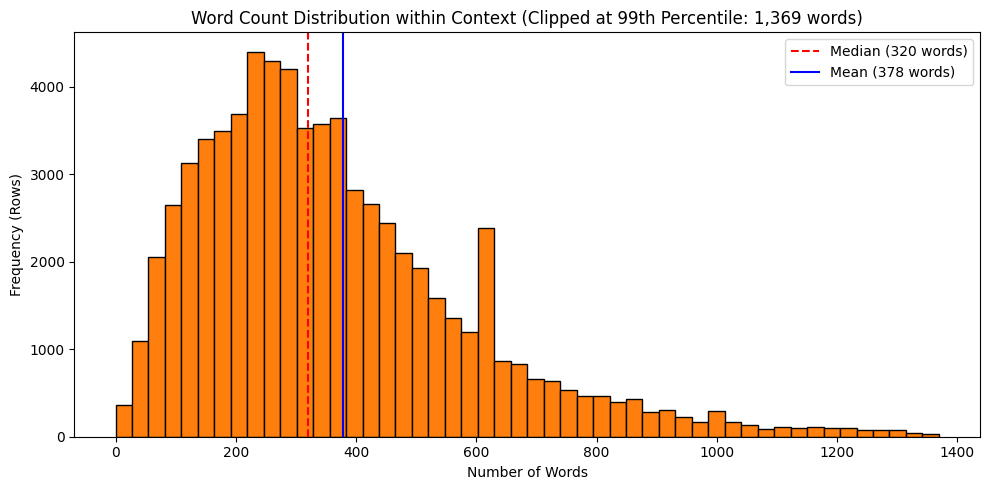

In [33]:
word_counts = lengths_df["word_count"]
p99_words = int(np.percentile(word_counts, 99))
median_val = word_counts.median()
mean_val = word_counts.mean()

plt.figure(figsize=(10, 5))
plt.hist(
    word_counts,
    bins=50,
    range=(0, p99_words),
    color="#ff7f0e",
    edgecolor="black",
)

plt.axvline(
    median_val,
    color="red",
    linestyle="dashed",
    linewidth=1.5,
    label=f"Median ({median_val:.0f} words)",
)
plt.axvline(
    mean_val,
    color="blue",
    linestyle="solid",
    linewidth=1.5,
    label=f"Mean ({mean_val:.0f} words)",
)

plt.title(f"Word Count Distribution within Context (Clipped at 99th Percentile: {p99_words:,} words)")
plt.xlabel("Number of Words")
plt.ylabel("Frequency (Rows)")
plt.legend()
plt.tight_layout()
plt.show()

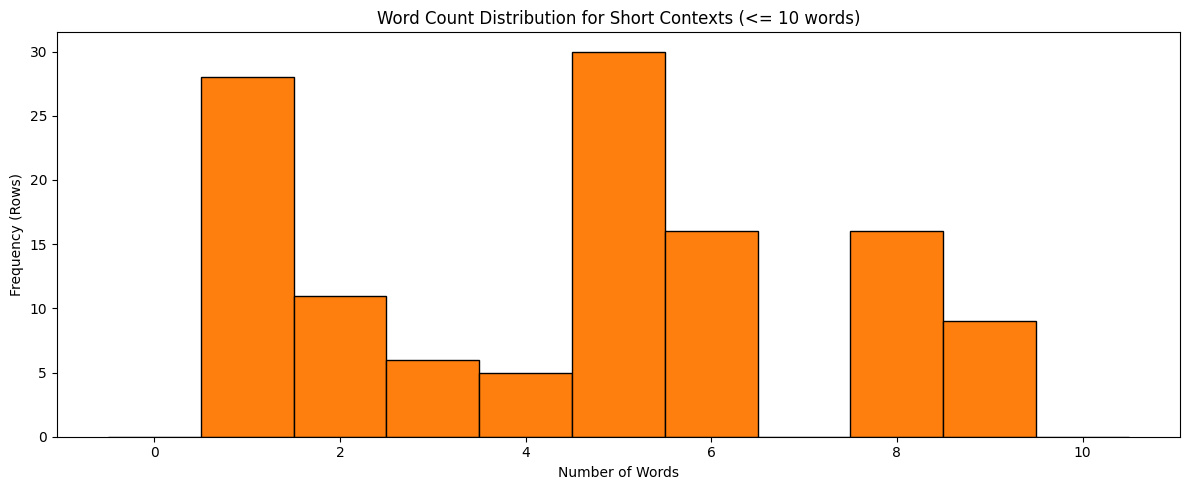

In [34]:
short_words = word_counts[word_counts <= 10]
plt.figure(figsize=(12, 5))
plt.hist(
    short_words,
    bins=np.arange(0, 12) - 0.5,
    color="#ff7f0e",
    edgecolor="black",
)
plt.title("Word Count Distribution for Short Contexts (<= 10 words)")
plt.xlabel("Number of Words")
plt.ylabel("Frequency (Rows)")
plt.tight_layout()
plt.show()

In [35]:
cleaned = df_clean["answer"].astype(str).str.strip()
mask = df_clean["answer"].notna() & ~cleaned.str.lower().isin(["", "no answer"])

answer_df = pd.DataFrame({
    "answer_count": df_clean.loc[mask, "answer"].str.split().str.len()
})

In [36]:
quantiles = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.50, 0.75, 0.8, 0.85, 0.90, 0.95, 0.99]
stats_summary = lengths_df.describe(percentiles=quantiles).round(1)

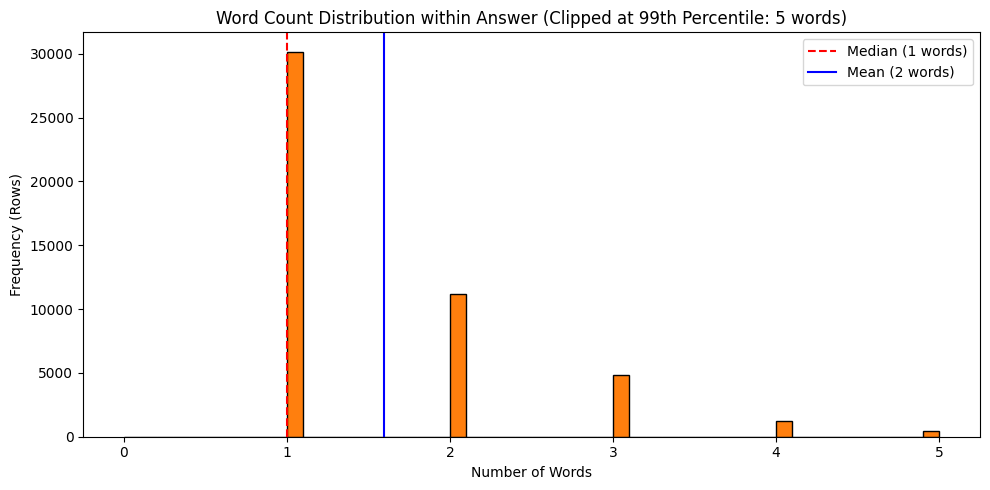

In [37]:
word_counts = answer_df["answer_count"]
p99_words = int(np.percentile(word_counts, 99))
median_val = word_counts.median()
mean_val = word_counts.mean()

plt.figure(figsize=(10, 5))
plt.hist(
    word_counts,
    bins=50,
    range=(0, p99_words),
    color="#ff7f0e",
    edgecolor="black",
)

plt.axvline(
    median_val,
    color="red",
    linestyle="dashed",
    linewidth=1.5,
    label=f"Median ({median_val:.0f} words)",
)
plt.axvline(
    mean_val,
    color="blue",
    linestyle="solid",
    linewidth=1.5,
    label=f"Mean ({mean_val:.0f} words)",
)

plt.title(f"Word Count Distribution within Answer (Clipped at 99th Percentile: {p99_words:,} words)")
plt.xlabel("Number of Words")
plt.ylabel("Frequency (Rows)")
plt.legend()
plt.tight_layout()
plt.show()

In [38]:
nltk.download("words", quiet=True)

True

In [39]:
ENGLISH_VOCAB = set(w.lower() for w in words.words())

In [40]:
def compute_english_word_ratio(text: str) -> float:
    """Computes the proportion of tokens that are recognizable English words."""
    if not isinstance(text, str) or not text.strip():
        return 0.0

    # Extract strictly alphabetic tokens, lowercase
    tokens = re.findall(r"\b[a-zA-Z]{2,}\b", text.lower())
    if not tokens:
        return 0.0

    valid_words = sum(1 for t in tokens if t in ENGLISH_VOCAB)
    return valid_words / len(tokens)

                          Row Count  Percentage (%)
text_category                                      
VALID_NATURAL_OR_TABULAR      69771           99.01
CSS_BOILERPLATE                 698            0.99


/tmp/ipykernel_16503/835400189.py:79: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index, y=counts.values, palette=colors[:len(counts)], edgecolor="black")


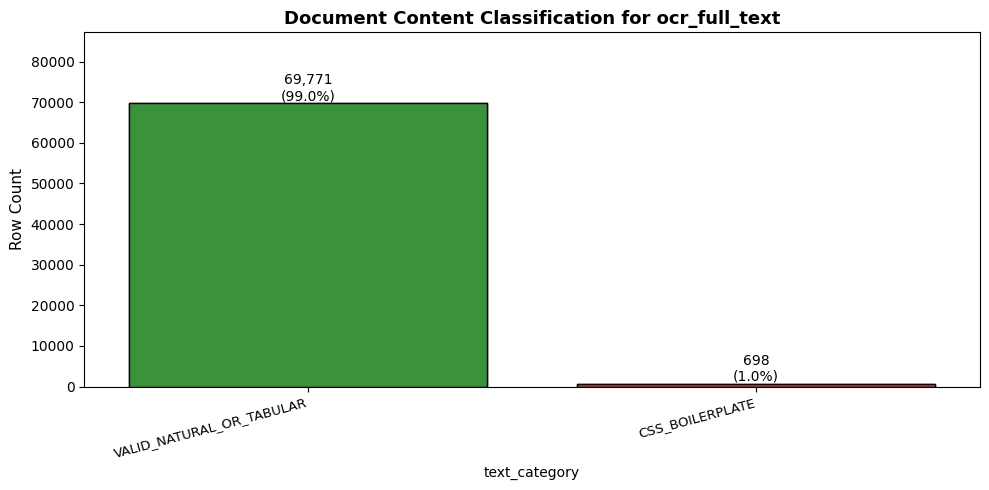

In [41]:
def score_text_validity(text: str) -> dict:
    if not isinstance(text, str) or not text.strip():
        return {
            "char_len": 0,
            "word_count": 0,
            "code_punct_ratio": 0.0,
            "css_pattern_hits": 0,
            "text_category": "EMPTY",
        }

    char_len = len(text)
    words = text.split()
    word_count = len(words)

    # 1. Code / Styling symbols ({}, ;, :, %, #, <>, \)
    code_symbols = sum(1 for c in text if c in "{};:#%<>\\")
    code_punct_ratio = code_symbols / char_len if char_len > 0 else 0.0

    # 2. Explicit CSS rule declarations
    css_patterns = re.findall(
        r"(\.mw-parser-output|display\s*:|font-size|font-weight|\bmargin\b|\bpadding\b|border-collapse)",
        text,
        re.IGNORECASE,
    )
    css_hits = len(css_patterns)

    # 3. Classification rules
    if css_hits > 1 or code_punct_ratio > 0.06:
        category = "CSS_BOILERPLATE"
    else:
        category = "VALID_NATURAL_OR_TABULAR"

    return {
        "char_len": char_len,
        "word_count": word_count,
        "code_punct_ratio": round(code_punct_ratio, 4),
        "css_pattern_hits": css_hits,
        "text_category": category,
    }


metrics_df = pd.DataFrame(df_clean["ocr_full_text"].apply(score_text_validity).tolist(), index=df_clean.index)
df_clean = pd.concat([df_clean, metrics_df], axis=1)

# Aggregate distribution
category_counts = df_clean["text_category"].value_counts()
ordered_cats = [
    "VALID_NATURAL_OR_TABULAR",
    "CSS_BOILERPLATE",
    "EMPTY",
]

ordered_cats = [c for c in ordered_cats if c in category_counts]
counts = category_counts[ordered_cats]
percentages = (counts / len(df_clean) * 100).round(2)

summary_df = pd.DataFrame({"Row Count": counts, "Percentage (%)": percentages})
print(summary_df.to_string())

# Plot Distribution Bar Chart
plt.figure(figsize=(10, 5))
colors = ["#2ca02c", "#d62728"]

bars = plt.bar(
    counts.index,
    counts.values,
    color=colors[: len(counts)],
    edgecolor="black"
)

plt.title(
    f"Document Content Classification for ocr_full_text",
    fontsize=13,
    fontweight="bold",
)
plt.ylabel("Row Count", fontsize=11)
plt.xticks(rotation=15, ha="right", fontsize=9.5)

ax = sns.barplot(x=counts.index, y=counts.values, palette=colors[:len(counts)], edgecolor="black")
ax.bar_label(ax.containers[0], labels=[f"{count:,}\n({percentage:.1f}%)" for count, percentage in zip(counts.values, percentages.values)])

plt.ylim(0, max(counts.values)*1.25)
plt.tight_layout()
plt.show()

###### We are dropping css boilerplate text to avoid poisioning context with non english words

In [42]:
total_before = len(df_clean)
css_mask = df_clean["text_category"] == "CSS_BOILERPLATE"
css_count = css_mask.sum()

print(f"Rows flagged CSS_BOILERPLATE to drop: {css_count:,} ({css_count / total_before * 100:.2f}%)")
df_clean = df_clean[~css_mask].copy().reset_index(drop=True)

print(f"Remaining clean rows: {len(df_clean):,}")

print("Updated Category Breakdown:")
print(df_clean["text_category"].value_counts(dropna=False).to_frame("Row Count"))

Rows flagged CSS_BOILERPLATE to drop: 698 (0.99%)
Remaining clean rows: 69,771
Updated Category Breakdown:
                          Row Count
text_category                      
VALID_NATURAL_OR_TABULAR      69771


# Is context suitable for QA (Does answer exist)?

In [43]:
# 1. Ensure tokenizers are available (punkt_tab is required in newer NLTK versions)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

True

In [44]:
def compress_text(text: str) -> str:
    """Removes all whitespace and non-alphanumeric characters, returning lowercase."""
    return re.sub(r"[^a-zA-Z0-9]", "", str(text)).lower()


def create_sentence_dataset(
    query: str,
    context: str,
    answer_text: str,
    lcs_threshold: float = 0.99,
) -> list[dict]:
    """Splits context into sentences and generates (query, sentence, label) pairs.

    - label=1: compressed sentence shares an LCS with compressed answer >= 99% of answer length.
    - label=0: negative sentence, or query is unanswerable (no answer).
    """
    if not isinstance(context, str) or not context.strip():
        return []

    # 1. Check if the question is answerable
    unanswerable_tokens = {"no answer"}
    clean_ans_raw = str(answer_text).strip().lower()

    if clean_ans_raw in unanswerable_tokens:
        is_answerable = False
        compressed_ans = ""
    else:
        compressed_ans = compress_text(clean_ans_raw)
        is_answerable = len(compressed_ans) > 0

    # 2. Normalize OCR newlines and tokenize into sentences
    normalized_context = context.replace("\n", ". ")
    sentences = nltk.sent_tokenize(normalized_context)

    dataset_pairs = []
    clean_query = str(query).strip()
    min_required_match = int(len(compressed_ans) * lcs_threshold) if is_answerable else 0

    # 3. Label generation using longest common substring
    for s in sentences:
        s_clean = s.strip()
        # Drop orphaned punctuation artifacts from newline normalization
        if not s_clean or s_clean in {".", "..", "..."}:
            continue

        label = 0
        if is_answerable:
            compressed_sent = compress_text(s_clean)

            # Fast path: exact substring match
            if compressed_ans in compressed_sent:
                label = 1
            else:
                # SequenceMatcher.find_longest_match finds the LCS
                matcher = SequenceMatcher(None, compressed_ans, compressed_sent, autojunk=False)
                match = matcher.find_longest_match(0, len(compressed_ans), 0, len(compressed_sent))

                if match.size >= min_required_match:
                    label = 1

        dataset_pairs.append({
            "query": clean_query,
            "sentence": s_clean,
            "label": label,
        })

    return dataset_pairs

In [45]:
def evaluate_dataset_row(row: pd.Series) -> dict:
    """Evaluates whether create_sentence_dataset found matching sentences

    and determines if the row should be kept or dropped.
    """
    pairs = create_sentence_dataset(
        query=row["question"],
        context=row["ocr_full_text"],
        answer_text=row["answer"],
    )

    clean_ans = str(row["answer"]).strip().lower()
    is_answerable = clean_ans not in {"no answer"}

    pos_count = sum(1 for p in pairs if p["label"] == 1)
    total_sentences = len(pairs)

    # Determine if we should drop
    if total_sentences == 0:
        drop_reason = "empty_context"
    elif is_answerable and pos_count == 0:
        drop_reason = "missing_positive_ground_truth"
    else:
        drop_reason = "keep"

    return {
        "pairs": pairs,
        "total_sentences": total_sentences,
        "positive_sentences": pos_count,
        "is_answerable": is_answerable,
        "drop_reason": drop_reason,
        "should_keep": drop_reason == "keep",
    }

###### Dropping around 2.9k of records since answer can't be found in context which is necessary for QA.

In [46]:
eval_results = df_clean.apply(evaluate_dataset_row, axis=1, result_type="expand")


df_eval = pd.concat([df_clean, eval_results], axis=1)

print("Drop vs Keep Breakdown:")
print(df_eval["drop_reason"].value_counts())

df_clean = df_eval[df_eval["should_keep"]].copy()
df_dropped = df_eval[~df_eval["should_keep"]].copy()

Drop vs Keep Breakdown:
drop_reason
keep                             66865
missing_positive_ground_truth     2906
Name: count, dtype: int64


In [47]:
sample_rows = df_dropped[["question", "answer", "ocr_full_text"]].sample(
    5, random_state=42
)

for idx, row in sample_rows.iterrows():
    print(f"--- Sample [Index: {idx}] ---")
    print(f"Question:  {row['question']}")
    print(f"Answer:    {row['answer']}")
    print(f"Full Text:\n{row['ocr_full_text']}\n")

--- Sample [Index: 4120] ---
Question:  When did the episode titled "Winterland" air for the first time? 
Answer:    november 12, 2007
Full Text:
Genre Romance Science fiction Created by Starring Kevin Falls Kevin McKidd Brian Howe Gretchen Egolf Moon Bloodgood Reed Diamond Charles Henry Wyson Theme music composer Amanda Ghost James Dring Jody Street Country of origin United States Original language English No. of seasons 1 No. of episodes 13 Production Executive Kevin Falls producers Alex Graves Running time 42 minutes Production Left Coast Productions companies 20th Century Fox Television Distributor 20th Television Release Original network NBC Picture format 480i (SDTV), 1080i (HDTV) Original release September 24 - December 19, 2007

--- Sample [Index: 18251] ---
Question:  What opponent has a score of 1-3?
Answer:    phillies
Full Text:
Other information Owner(s) Craig F. Cullinan, Jr., Roy Hofheinz General Paul Richards manager(s) Manager(s) Harry Craft Local television KTRK (Al H

###### We see the dropped contexts barely has the answer

In [48]:
df_clean["should_keep"].value_counts()

,count
should_keep,
True,66865


In [49]:
df_clean = df_clean[['question', 'answer', 'ocr_full_text', 'pairs', 'positive_sentences', 'image']]

In [50]:
df_clean.rename(columns={'ocr_full_text': 'context'}, inplace=True)

In [51]:
df_clean.iloc[0]['pairs']

[{'query': 'was chile below or above the gold medal count for panama?',
  'sentence': 'Event Gold Silver Bronze 100 metres Beatriz Allocco Argentina 11.7 =CR Carmela Bolívar Peru 11.8 Esmeralda García Brazil 11.8 200 metres Beatriz Allocco Argentina 23.5 Tania Miranda Brazil 24.1 Esmeralda García Brazil 24.1 400 metres Tania Miranda Brazil 54.2 CR Margarita Grün Uruguay 54.8 Miriam Rojas Colombia 54.8 800 metres Alejandra Ramos Chile 2:04.2 CR Nancy González Chile 2:09.8 Adriana Marchena Venezuela 2:10.4 1500 metres Alejandra Ramos Chile 4:23.2 CR Teresa Rodríguez Colombia 4:32.6 Monica Regonesi Chile 4:36.1 100 metres hurdles Yvonne Neddermann Argentina 14.2 Olga Verissimo Brazil 14.4 Beatriz Capotosto Argentina 14.7 High jump Ana Maria Marcón Brazil 1.75 Liliana Arigoni Argentina 1.75 Beatriz Bonfim Brazil 1.70 Long jump Themis Zambrzycki Brazil 6.03 Conceição Geremias Brazil 5.95 Yvonne Neddermann Argentina 5.92 Shot put Magdalena Gómez Colombia 13.94 Themis Zambrzycki Brazil 13.84 

# Final Verification

#

In [52]:
is_no_answer = (
    df_clean["answer"].fillna("").astype(str).str.strip().str.lower()
    == "no answer"
)

df_no_answer = df_clean[is_no_answer]
df_has_answer = df_clean[~is_no_answer]

print(f"Shape: {df_clean.shape}")
print(f"No Answer:  {len(df_no_answer):,} ({len(df_no_answer)/len(df_clean)*100:.1f}%)")
print(f"Has Answer: {len(df_has_answer):,} ({len(df_has_answer)/len(df_clean)*100:.1f}%)")

Shape: (66865, 6)
No Answer:  21,930 (32.8%)
Has Answer: 44,935 (67.2%)


# Split train, test, and validate (80/10/10)

In [53]:
train_df, temp_df = train_test_split(
    df_clean, test_size=0.20, random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42
)

In [54]:
print("train: ", len(train_df))
print("val: ", len(val_df))
print("test: ", len(test_df))

train:  53492
val:  6686
test:  6687


# Load dataset to Google drive

In [55]:
def save_split(
    df: pd.DataFrame, split: str, filename: str = 'data.parquet'
) -> bool:
  """Saves df to Google Drive if it hasn't been saved already.

  split: Train, Val, or Test
  """
  folder = f'/content/drive/MyDrive/266_Final/data/{split}'
  os.makedirs(folder, exist_ok=True)

  path = os.path.join(folder, filename)

  # Check if already saved
  if os.path.exists(path):
    print(f'[{split}] Already exists at {path}. Skipping.')
    return False

  # Save and set flag
  df.to_parquet(path, index=False)
  print(f'[{split}] Successfully saved to {path}.')
  return True

In [56]:
save_split(train_df, 'Train')
save_split(val_df, 'Val')
save_split(test_df, 'Test')

[Train] Already exists at /content/drive/MyDrive/266_Final/data/Train/data.parquet. Skipping.
[Val] Already exists at /content/drive/MyDrive/266_Final/data/Val/data.parquet. Skipping.
[Test] Already exists at /content/drive/MyDrive/266_Final/data/Test/data.parquet. Skipping.


False

# Final EDA

###### See word count for question and answer post filtering once more.

In [57]:
df_clean["word_count"] = (
    df_clean["context"].fillna("").astype(str).str.split().apply(len)
)

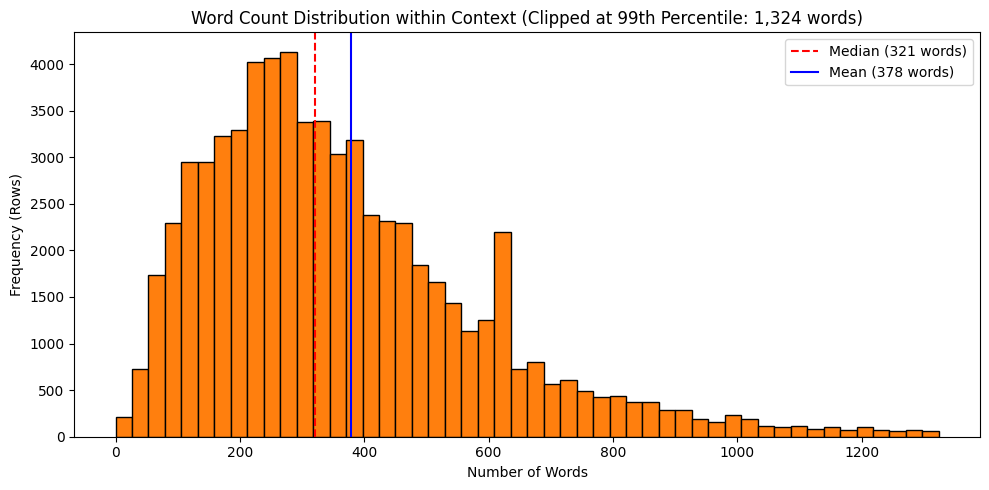

In [58]:
word_counts = df_clean["word_count"]
p99_words = int(np.percentile(word_counts, 99))
median_val = word_counts.median()
mean_val = word_counts.mean()

plt.figure(figsize=(10, 5))
plt.hist(
    word_counts,
    bins=50,
    range=(0, p99_words),
    color="#ff7f0e",
    edgecolor="black",
)

plt.axvline(
    median_val,
    color="red",
    linestyle="dashed",
    linewidth=1.5,
    label=f"Median ({median_val:.0f} words)",
)
plt.axvline(
    mean_val,
    color="blue",
    linestyle="solid",
    linewidth=1.5,
    label=f"Mean ({mean_val:.0f} words)",
)

plt.title(f"Word Count Distribution within Context (Clipped at 99th Percentile: {p99_words:,} words)")
plt.xlabel("Number of Words")
plt.ylabel("Frequency (Rows)")
plt.legend()
plt.tight_layout()
plt.show()

In [59]:
df_clean["answer_count"] = (
    df_clean["answer"].fillna("").astype(str).str.split().apply(len)
)

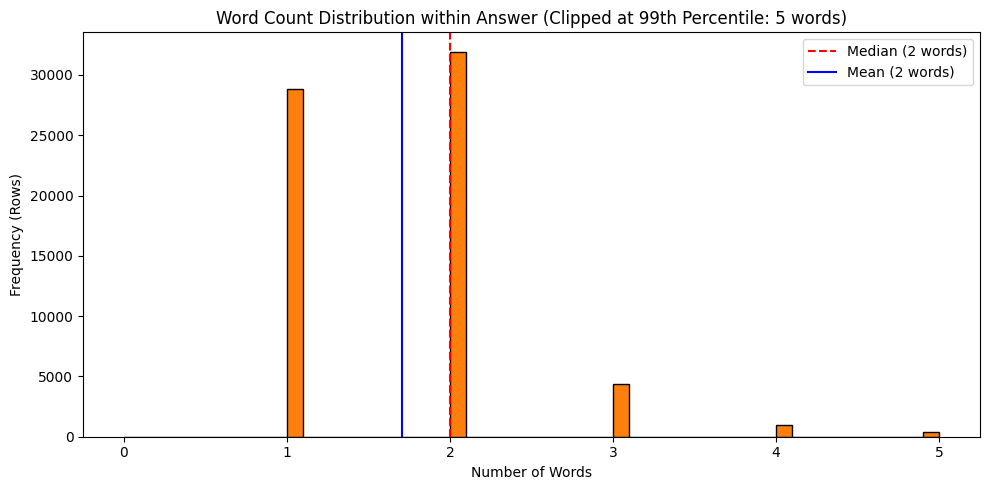

In [60]:
word_counts = df_clean["answer_count"]
p99_words = int(np.percentile(word_counts, 99))
median_val = word_counts.median()
mean_val = word_counts.mean()

plt.figure(figsize=(10, 5))
plt.hist(
    word_counts,
    bins=50,
    range=(0, p99_words),
    color="#ff7f0e",
    edgecolor="black",
)

plt.axvline(
    median_val,
    color="red",
    linestyle="dashed",
    linewidth=1.5,
    label=f"Median ({median_val:.0f} words)",
)
plt.axvline(
    mean_val,
    color="blue",
    linestyle="solid",
    linewidth=1.5,
    label=f"Mean ({mean_val:.0f} words)",
)

plt.title(f"Word Count Distribution within Answer (Clipped at 99th Percentile: {p99_words:,} words)")
plt.xlabel("Number of Words")
plt.ylabel("Frequency (Rows)")
plt.legend()
plt.tight_layout()
plt.show()

###### See types of extracted text from Amazon Textract. In QA, tabular QA models can be more useful for tables/charts rather than a regular QA model like SpanBert.

In [61]:
def classify_extracted_text(text: str) -> str:
    """Classify extracted text into Pure Paragraph, Table/Chart, or Hybrid Context
    """
    lines = [line.strip() for line in text.split("\n") if line.strip()]
    tokens = re.findall(r"\b\w+\b", text)


    # 1. Measure Numerical & Symbol Density
    num_tokens = sum(1 for t in tokens if t.replace(".", "", 1).isdigit())
    num_ratio = num_tokens / len(tokens) if tokens else 0.0

    # 2. Measure Complete Sentence Punctuation Ratio
    # Sentences typically end with '.', '!', or '?'
    sentence_endings = sum(
        1 for line in lines if line.endswith((".", "!", "?"))
    )
    sentence_ratio = sentence_endings / len(lines) if lines else 0.0

    # 3. Average Tokens per Line
    avg_tokens_per_line = len(tokens) / len(lines) if lines else 0.0

    # Classification Rules
    if (
        sentence_ratio > 0.65
        and num_ratio < 0.08
        and avg_tokens_per_line > 7.0
    ):
        return "Pure Paragraph"
    elif sentence_ratio < 0.20 and (
        num_ratio > 0.25 or avg_tokens_per_line <= 4.0
    ):
        return "Table / Chart"
    else:
        return "Hybrid Context"

In [62]:
df_clean["text_type"] = (
    df_clean["context"].fillna("").astype(str).apply(classify_extracted_text)
)

(0.0, 13709.85)

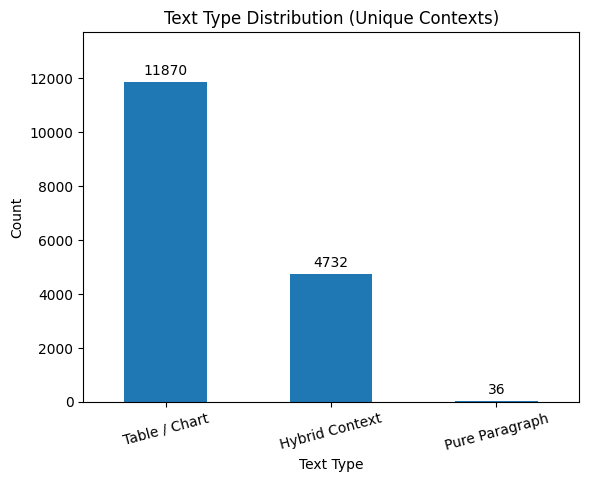

In [63]:
counts = (
    df_clean.drop_duplicates(subset=["context"])["text_type"]
    .value_counts()
)

ax = counts.plot(
    kind="bar",
    title="Text Type Distribution (Unique Contexts)",
    xlabel="Text Type",
    ylabel="Count",
    rot=15,
)

ax.bar_label(ax.containers[0], padding=3)
ax.set_ylim(0, ax.get_ylim()[1] * 1.1)